In [1]:
%load_ext autoreload
%autoreload 2

import xr_ccew as tw
import xarray as xr
import numpy as np
import pandas as pd
from scipy import ndimage
import scipy.stats as stats
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.signal import hilbert
from src.loading import (
    load_noaa_daily_olr,
    load_wave_filtered_olr,
    load_wave_event_record
)
from src.spectral_power import (
    spectral_power_pipeline,
    add_matsuno_curves
)
from src.constants import *

from src.wave_profiles import BOX_PROFILES as profiles

from IPython.display import clear_output

In [2]:
def implied_gravity_wave_speed(wave: str, phase_speed, width_deg, U=0.0):
  

    p = phase_speed - U

    assert np.isfinite(p) and np.isfinite(width_deg) and width_deg > 0

    # Width represents half a wavelength.
    k = np.pi / (EARTH_RADIUS * np.deg2rad(width_deg))

    if wave == "Kelvin":
        if p <= 0:
            return np.nan

        return p

    if wave in ("MRG", "n0EIG"):
        if wave == "MRG" and p >= 0:
            return np.nan
        if wave == "n0EIG" and p <= 0:
            return np.nan

        denominator = BETA + k**2 * p
        if denominator <= 0:
            return np.nan

        return (k * p)**2 / denominator

    if wave == "n1ERW":
        if p >= 0:
            return np.nan

        A = k**2 + BETA / p
        B = 3 * BETA
        omega_squared = (k * p)**2

        if A >= 0:
            return np.nan  # No finite positive ER solution.

        discriminant = B**2 + 4 * A * omega_squared

        # Larger positive root.
        return (-B - np.sqrt(discriminant)) / (2 * A)

    if wave == "n1WIG":
        if p >= 0:
            return np.nan

        A = k**2 + BETA / p
        B = 3 * BETA
        omega_squared = (k * p)**2
        discriminant = B**2 + 4 * A * omega_squared

        # Smaller positive root, avoiding numerical cancellation.
        return 2 * omega_squared / (B + np.sqrt(discriminant))

    raise ValueError(f"Unsupported wave: {wave}")

In [3]:
wave_event_records = {p: load_wave_event_record(p) for p in list(profiles.keys())}

In [6]:
wave_event_records['Kelvin']['mean_width_deg']

0       30.712966
1       67.787218
2       19.663987
3       36.241332
4       36.226460
          ...    
1607    35.598458
1608    55.920985
1609    35.554251
1610    48.111531
1611    38.811368
Name: mean_width_deg, Length: 1612, dtype: float64

In [7]:
wave_event_records['Kelvin']

,wave,start,stop,start_lon_min,start_lon_max,stop_lon_min,stop_lon_max,lat_min,lat_max,max_olr_sigma,min_olr_sigma,mean_width_deg,max_width_deg,min_width_deg,radon_m_s,extent_duration_m_s
0,Kelvin,1990-02-22 12:00:00,1990-02-26 12:00:00,144.357508,169.417147,174.427240,214.994438,0.5,19.5,-1.505688,-2.161341,30.712966,40.567198,23.817747,11.5,11.936806
1,Kelvin,1990-03-16 12:00:00,1990-03-20 12:00:00,-99.056259,-39.295651,-21.954031,62.196776,0.5,19.5,-1.504141,-2.136183,67.787218,84.150807,51.497214,13.5,12.228149
2,Kelvin,1990-03-22 12:00:00,1990-03-27 12:00:00,-149.412087,-129.478630,-114.703902,-96.286493,0.5,19.5,-1.500621,-3.818448,19.663987,22.324970,17.835958,9.0,8.625025
3,Kelvin,1990-03-23 12:00:00,1990-03-29 12:00:00,161.864000,185.056832,194.212212,238.584584,0.5,19.5,-1.503154,-3.968020,36.241332,47.529265,23.192832,11.0,9.995592
4,Kelvin,1990-03-30 12:00:00,1990-04-11 12:00:00,-25.026928,48.850182,144.804358,164.246107,0.5,19.5,-1.504892,-5.581453,36.226460,73.877111,19.441748,13.0,12.431926
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1607,Kelvin,2025-07-10 12:00:00,2025-07-27 12:00:00,51.718340,77.396000,219.975247,268.212081,0.5,19.5,-1.505892,-5.023050,35.598458,51.003226,25.677660,13.5,12.794652
1608,Kelvin,2025-07-11 12:00:00,2025-07-19 12:00:00,123.673404,170.221089,215.455323,281.547807,0.5,19.5,-1.506352,-2.771830,55.920985,73.013753,46.547686,15.5,15.074438
1609,Kelvin,2025-07-31 12:00:00,2025-08-11 12:00:00,67.273260,87.856165,158.419812,182.928697,0.5,19.5,-1.502647,-3.103920,35.554251,52.953588,20.582905,11.0,10.698585
1610,Kelvin,2025-09-09 12:00:00,2025-09-13 12:00:00,109.109403,176.013059,201.738654,245.051073,0.5,19.5,-1.506282,-2.620146,48.111531,66.903656,38.994742,17.0,15.741359


TypeError: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

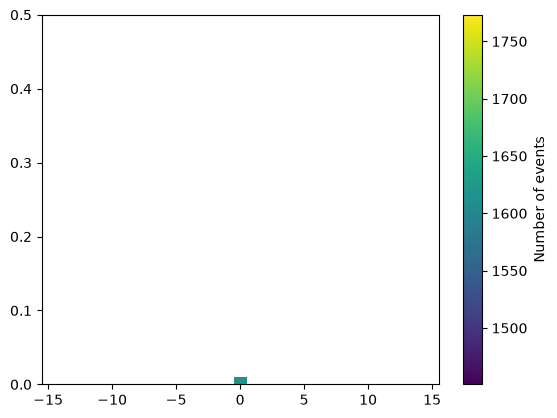

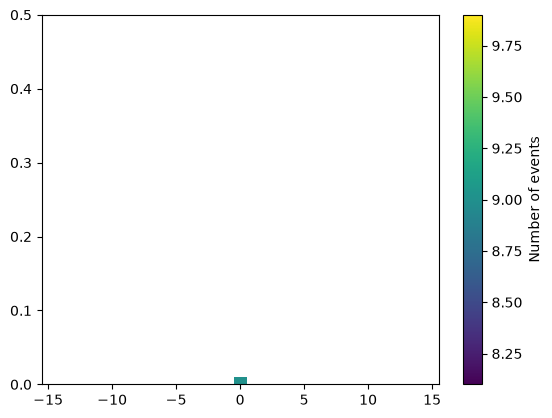

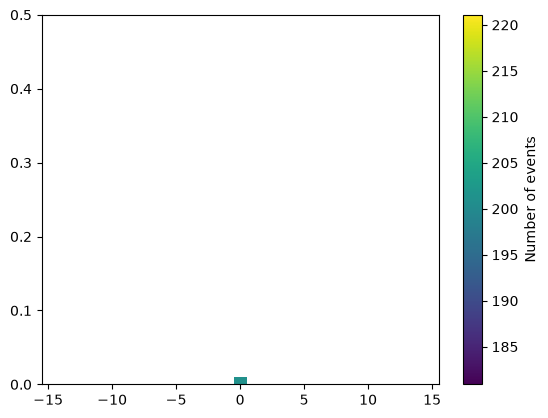

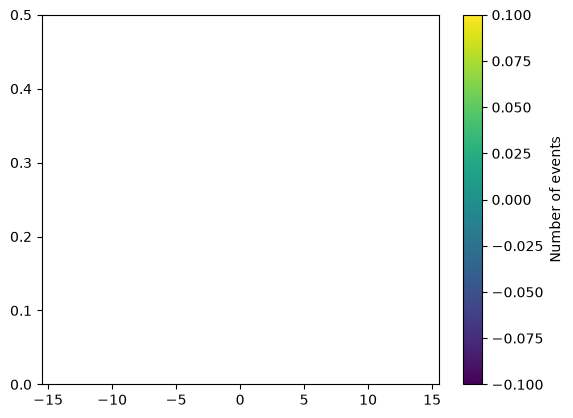

In [ ]:
for wave in profiles:
    events = wave_event_records[wave]

    event_k = np.pi / (EARTH_RADIUS * np.deg2rad(events['mean_width_deg']))
    event_cp = events['radon_m_s']
    event_omega = event_k * event_cp

    event_K = np.sign(event_cp) * event_k * EARTH_RADIUS
    event_frequency = np.abs(event_omega) * 86400 / (2 * np.pi)

    k_bins = np.arange(-15.5, 16.5, 1)
    omega_bins = np.linspace(0, 0.5, 51)  # cycles/day

    count, omega_edges, k_edges, _  = stats.binned_statistic_2d(
        event_omega,
        event_k,
        values = None,
        statistic='count',
        bins=[omega_bins, k_bins]        
    )

    fig, ax = plt.subplots()
    mesh = ax.pcolormesh(
        k_edges,
        omega_edges,
        np.ma.masked_equal(count, 0),
        shading="auto",
        cmap="viridis",
    )

    fig.colorbar(mesh, ax=ax, label="Number of events")


In [ ]:

for wave, events in wave_event_records.items():
    for estimator in ["radon", "extent_duration"]:
        events[f"c0_{estimator}_m_s"] = events.apply(
            lambda row: implied_gravity_wave_speed(
                wave=wave,
                phase_speed=row[f"{estimator}_m_s"],
                width_deg=row["mean_width_deg"],
            ),
            axis=1,
            result_type="reduce",
        )

        events[f"h_{estimator}_m"] = (
            events[f"c0_{estimator}_m_s"]**2 / 9.81
        )

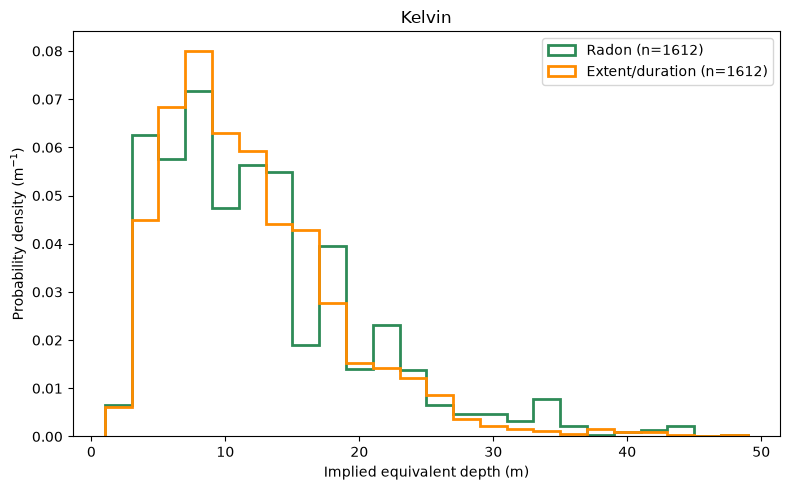

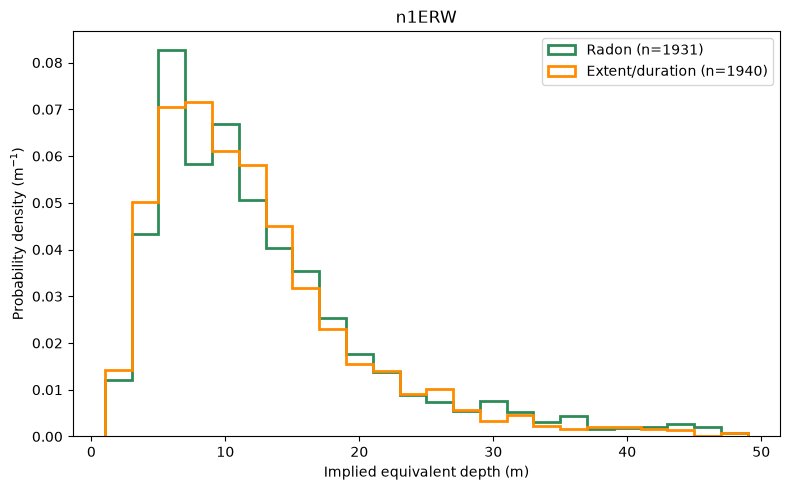

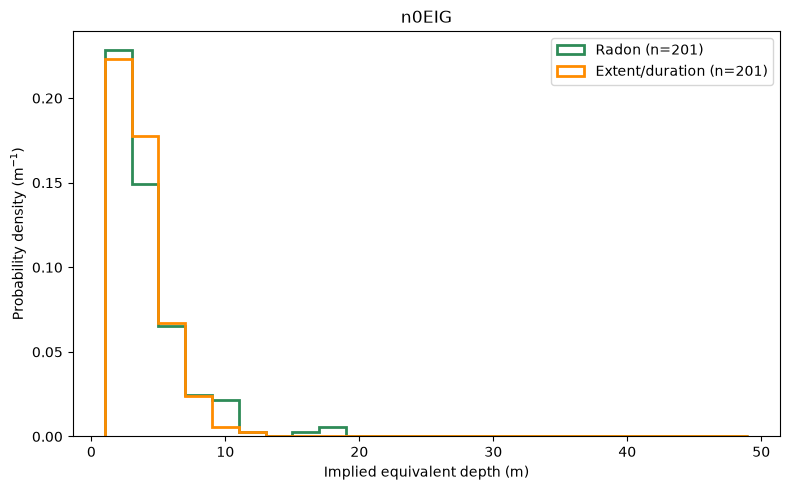

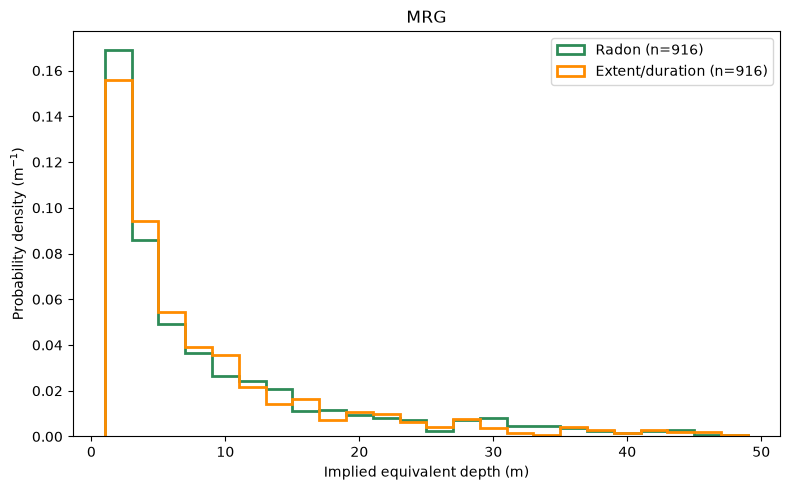

In [6]:

depth_columns = {
    "h_radon_m": ("Radon", "seagreen"),
    "h_extent_duration_m": ("Extent/duration", "darkorange"),
}

for wave, events in wave_event_records.items():
    depths = events[list(depth_columns)].replace(
        [np.inf, -np.inf], np.nan
    )
    combined = depths.stack().dropna()

    if combined.empty:
        continue

    # Shared bins for both estimates.
    bins  = np.arange(1, 50, 2)

    fig, ax = plt.subplots(figsize=(8, 5))

    for column, (label, color) in depth_columns.items():
        values = depths[column].dropna()
        if values.empty:
            continue

        ax.hist(
            values,
            bins=bins,
            histtype="step",
            linewidth=2,
            density=True,
            color=color,
            label=f"{label} (n={len(values)})",
        )

    ax.set(
        xlabel="Implied equivalent depth (m)",
        ylabel="Probability density (m$^{-1}$)",
        title=wave,
    )
    ax.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
THRESH_SIGMA = 1.5
MIN_DURATION_DAYS = 3.0

event_records = []

for profile in profiles:
    wave_data = load_wave_filtered_olr(profile)
    field = wave_data.sel(
        {
            "lat": slice(0, None)
        }
    )

    hov = (
        field.weighted(np.cos(np.deg2rad(field.lat)))
        .mean("lat")
        .transpose("time", "lon")
        .compute()
    )

    olr_std = hov.std().item()
    event_threshold = THRESH_SIGMA * olr_std
    candidate_event_mask = hov <= -event_threshold

    # Eight-neighbour connectivity includes diagonally touching pixels.
    labels, n_candidates = ndimage.label(
        candidate_event_mask,
        structure=np.ones((3, 3), dtype=bool),
    )
    candidate_slices = ndimage.find_objects(labels)


    for event_id, (time_slice, lon_slice) in enumerate(candidate_slices, start=1):
        clear_output()
        print(f'Processing  {profile} Event {event_id} of {len(candidate_slices)}')


        event_hov = hov.isel(time=time_slice, lon=lon_slice)
        event_mask = xr.DataArray(
            labels[time_slice, lon_slice] == event_id,
            dims=event_hov.dims,
            coords=event_hov.coords,
        )

        # Check duration
        duration_days = (
            (event_hov.time[-1] - event_hov.time[0]) / np.timedelta64(1, "D")
        ).item()

        if duration_days <= MIN_DURATION_DAYS:
            continue
        print(duration_days)


        #
        # Get event widths for each time
        #
        widths = xr.full_like(event_hov.time, float("nan"), dtype=float)

        for t in event_hov.time:
            event_row = event_hov.sel(time=t).where(event_mask.sel(time=t))
            if not (event_row < 0).any().item():
                continue

            trough_lon = event_row.idxmin("lon").item()
            row = hov.sel(time=t).sortby("lon")

            # Copies on either side allow the search to cross the longitude seam.
            row = xr.concat([
                row.assign_coords(lon=row.lon - 360),
                row,
                row.assign_coords(lon=row.lon + 360),
            ], dim="lon")

            left = row.where(
                (row.lon < trough_lon) & (row >= 0), drop=True
            )
            right = row.where(
                (row.lon > trough_lon) & (row >= 0), drop=True
            )

            if not left.sizes["lon"] or not right.sizes["lon"]:
                continue

            segment = row.sel(lon=slice(
                left.lon.max().item(),
                right.lon.min().item(),
            ))
            if not segment.notnull().all().item():
                continue

            left_outer = segment.isel(lon=0)
            left_inner = segment.isel(lon=1)
            right_inner = segment.isel(lon=-2)
            right_outer = segment.isel(lon=-1)

            left_zero = (
                left_outer.lon
                - left_outer * (left_inner.lon - left_outer.lon)
                / (left_inner - left_outer)
            )
            right_zero = (
                right_inner.lon
                - right_inner * (right_outer.lon - right_inner.lon)
                / (right_outer - right_inner)
            )

            widths.loc[{"time": t}] = (right_zero - left_zero).item()

        #
        # Get phase speeds for each wave event
        #
        metres_per_degree = 2 * np.pi * 6_371_000 / 360

        # Preserve all event timestamps.
        amplitude = (
            (-event_hov).where(event_mask, 0)
            .clip(min=0)
            .fillna(0)
        )
        amplitude = amplitude.reindex(
            lon=hov.lon, fill_value=0
        ).sortby("lon")

        elapsed_seconds = (
            (amplitude.time - amplitude.time[0])
            / np.timedelta64(1, "s")
        )

        # Circular amplitude-weighted centre.
        angle = np.deg2rad(amplitude.lon)
        centre_lon = np.rad2deg(np.arctan2(
            (amplitude * np.sin(angle)).sum("lon"),
            (amplitude * np.cos(angle)).sum("lon"),
        ))

        # Unwrap movement across the longitude seam.
        steps = (centre_lon.diff("time") + 180) % 360 - 180
        centre_unwrapped = xr.concat([
            centre_lon.isel(time=slice(0, 1)),
            centre_lon.isel(time=0) + steps.cumsum("time"),
        ], dim="time")

        speed_extent = (
            (centre_unwrapped[-1] - centre_unwrapped[0])
            * metres_per_degree / elapsed_seconds[-1]
        ).item()

        # Periodic field for the Radon projections.
        periodic_amplitude = xr.concat([
            amplitude.assign_coords(lon=amplitude.lon - 360),
            amplitude,
            amplitude.assign_coords(lon=amplitude.lon + 360),
        ], dim="lon")

        origins = amplitude.lon.rename({"lon": "origin"})
        lon_min = amplitude.lon.min().item()

        radon_scores = xr.DataArray(
            float("nan"),
            dims=["speed"],
            coords={"speed": np.linspace(-50, 50, 201)},
        )

        for speed in radon_scores.speed:
            path = (
                origins
                + speed.item() * elapsed_seconds / metres_per_degree
            )
            path = (path - lon_min) % 360 + lon_min

            along_paths = periodic_amplitude.interp(lon=path)
            projection = (
                along_paths.assign_coords(time=elapsed_seconds)
                .integrate("time")
            )
            radon_scores.loc[{"speed": speed}] = (
                projection**2
            ).sum("origin").item()

        speed_radon = radon_scores.idxmax("speed").item()

        phase_speeds = xr.DataArray(
            [speed_radon, speed_extent],
            dims=["estimator"],
            coords={"estimator": ["radon", "extent_duration"]},
            name="phase_speed",
            attrs={"units": "m s-1", "positive": "eastward"},
        )

        #
        # Record event information
        #
        event_records.append({
            "wave": profile,
            "start": event_hov.time.values[0],
            "stop": event_hov.time.values[-1],
            "max_olr_sigma": event_hov.where(event_mask).max().item() / olr_std,
            "min_olr_sigma": event_hov.where(event_mask).min().item() / olr_std,
            "mean_width_deg": widths.mean("time").item(),
            "max_width_deg": widths.max("time").item(),
            "min_width_deg": widths.min("time").item(),
            "radon_m_s": phase_speeds.sel(
                estimator="radon"
            ).item(),
            "extent_duration_m_s": phase_speeds.sel(
                estimator="extent_duration"
            ).item(),
        })

events = pd.DataFrame(event_records)   

Processing  Kelvin Event 3520 of 10863
3.0


KeyboardInterrupt: 